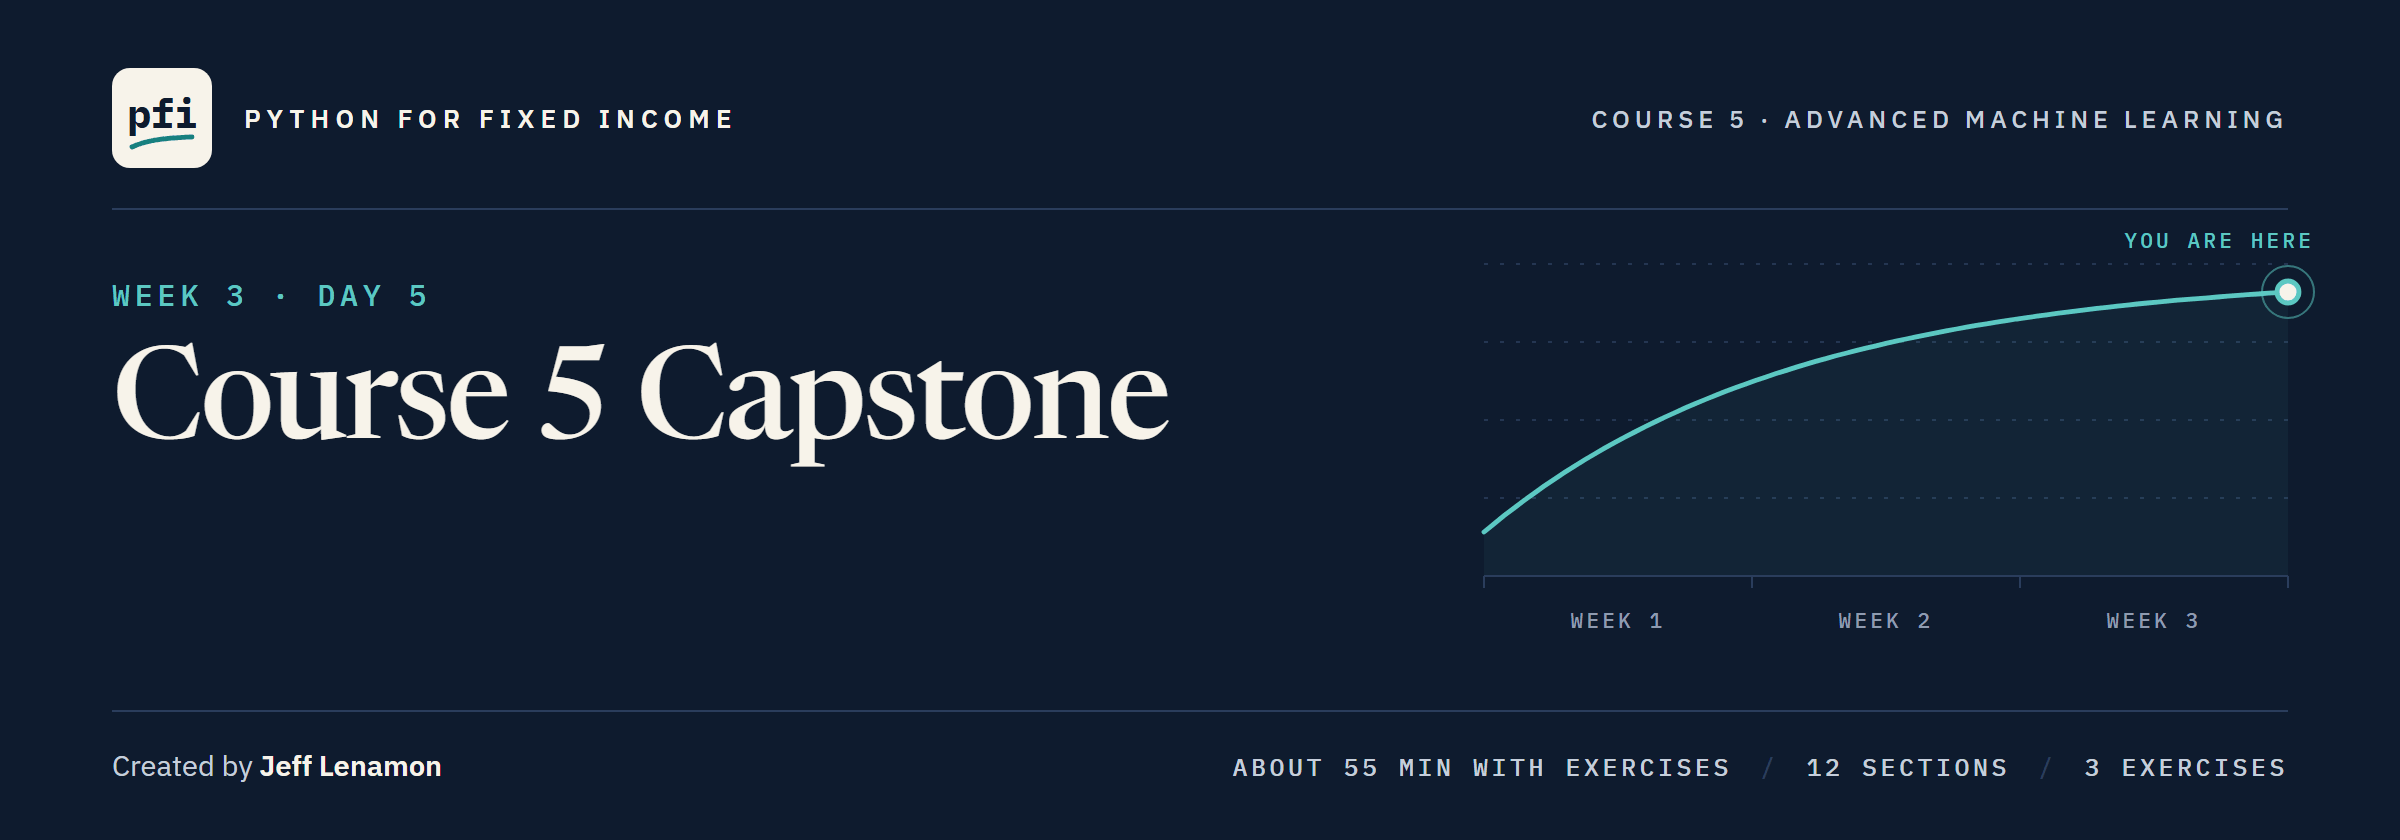

# Course 5 Capstone

Week 3, Day 5. Run the whole course on a file you have never seen, choose everything on folds, open the test rows once, and say how sure anyone can be.

**Data:** `taiwan_bankruptcy.csv`, 6,819 rows of company financial ratios from the Taiwan Economic Journal, 1999 to 2009: **real**, UCI Machine Learning Repository dataset 572, CC BY 4.0. Citation: Taiwanese Bankruptcy Prediction [Dataset]. (2020). UCI Machine Learning Repository. https://doi.org/10.24432/C5004D.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day5/course5_capstone.ipynb)

# Problem Statement

## Business Context

A colleague who covers Asian corporates hands you a public file of Taiwanese companies' financial ratios, with a flag for the ones that went bankrupt.
The [dataset page](https://doi.org/10.24432/C5004D) says the data cover 1999 to 2009 and bankruptcy follows the Taiwan Stock Exchange's regulations, with no units, no horizon and no company identifier, so this notebook speaks of rows.
It is one market in one period, and that market differs from US credit.
She asks which of four models best separates bankrupt rows it never saw, how sure 44 bankrupt test rows let anyone be, and what the chosen model leans on.
Its output is "the model's probability of bankruptcy in this file", never a credit view on any company.
The work is yours: each question has an empty cell and a `check()` line.

## Objectives

Describe a new file's columns, copies and scales, and split it once.
Compare four models on folds, tune the leader honestly, and choose weights, resampling and a threshold out of fold.
Open the test rows once, put an interval on each score, and describe the chosen model with SHAP values on rows it never saw.

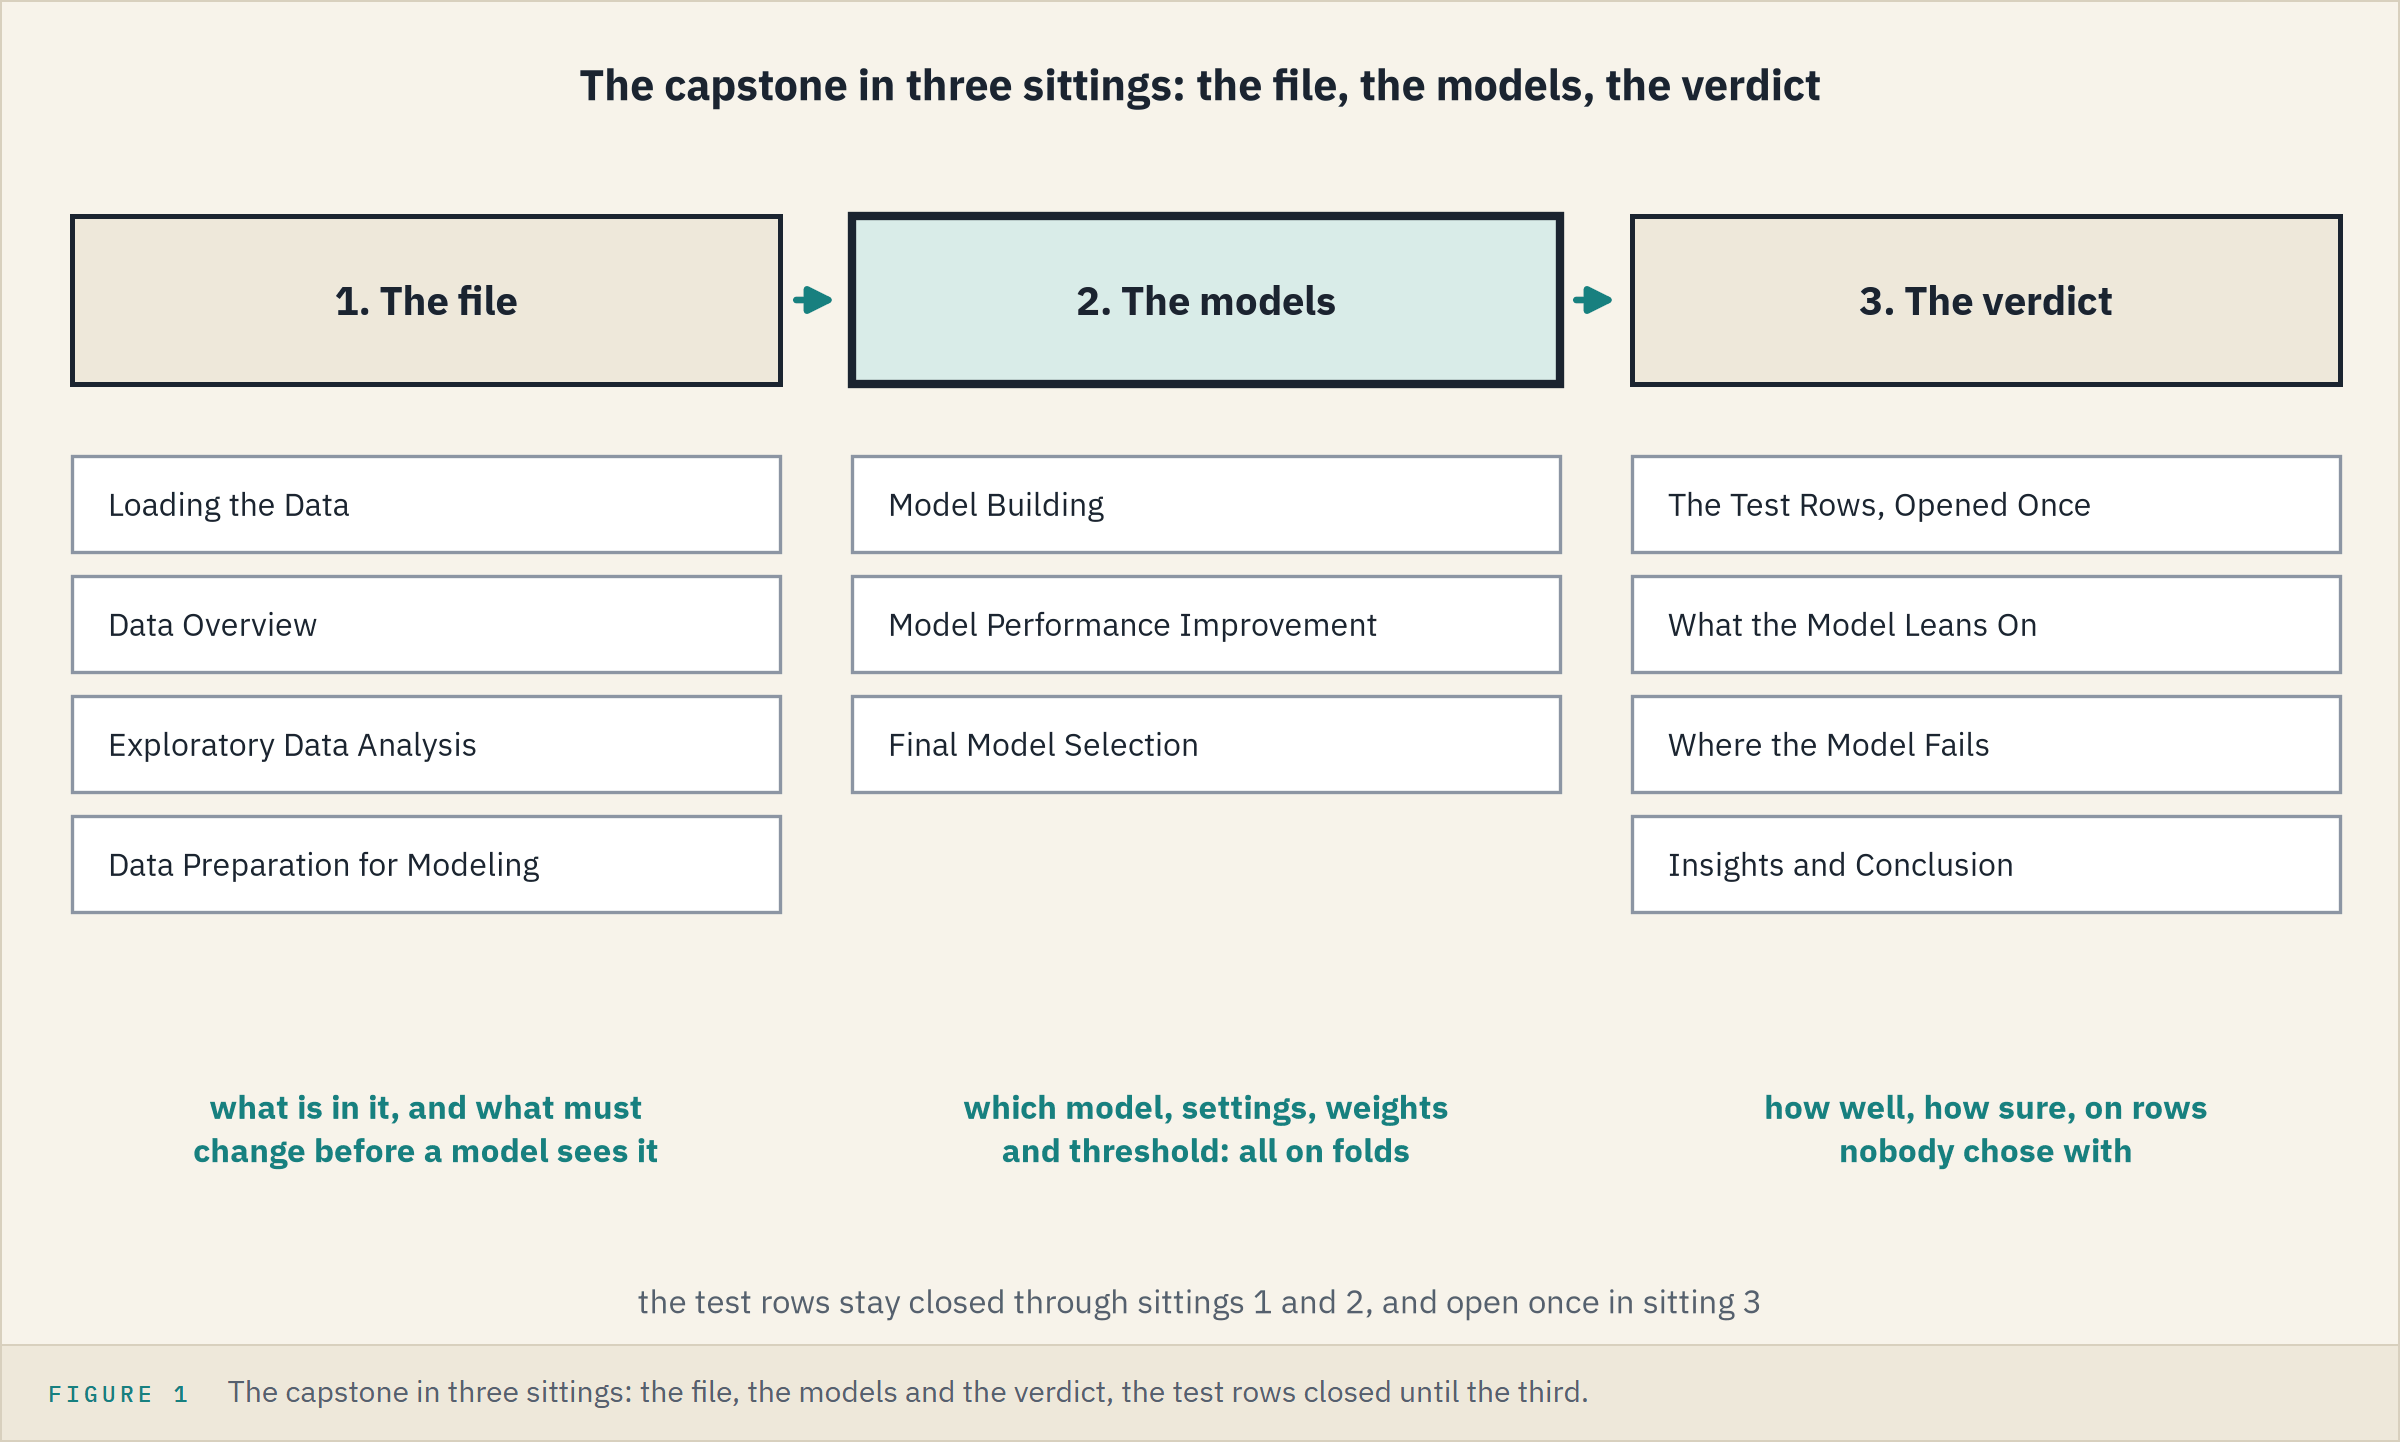

## Data Dictionary

`taiwan_bankruptcy.csv`, one row per set of a company's ratios:

1. `Bankrupt?`: 1 if the company went bankrupt, **the target**
2. 95 features under their own names; the page's X1 to X95 list runs in another order, so it is quoted nowhere as a definition

The loader strips each name's leading space and the space and yen sign that end three names: the only changes to the file.

## Your Route Through Day 5

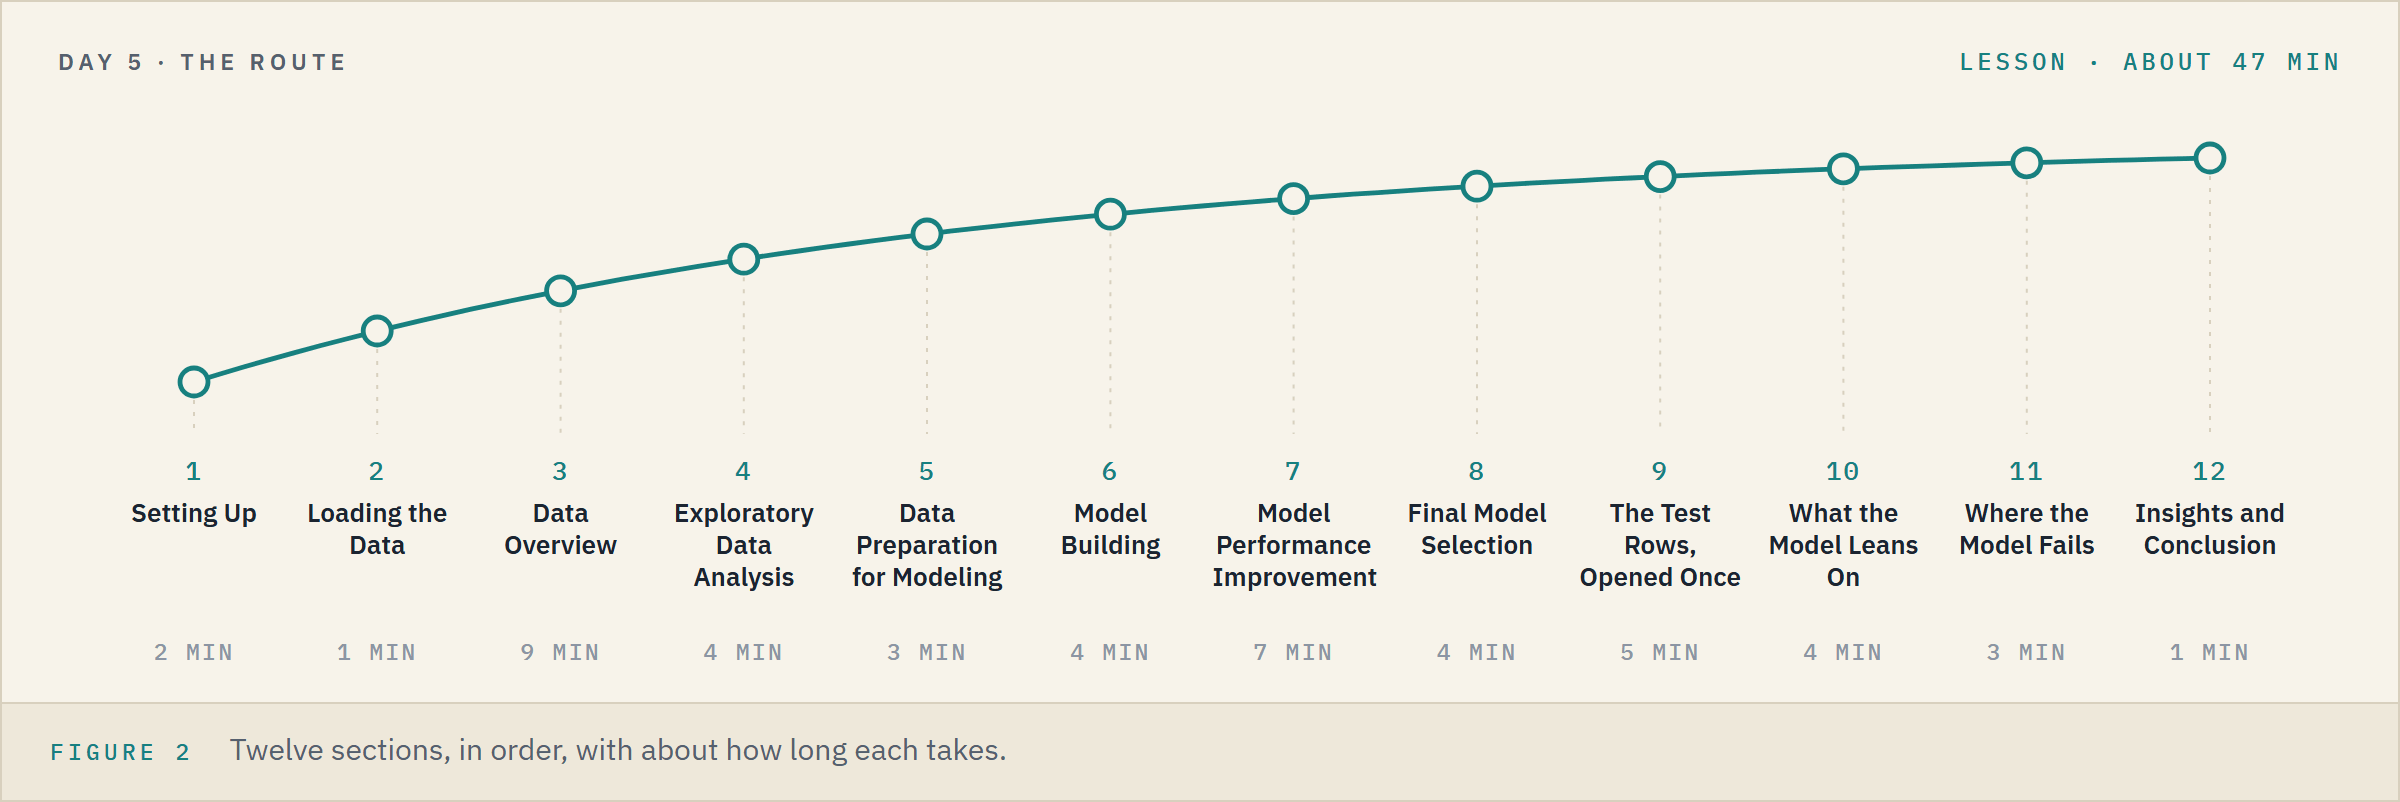

**Time.** About 47 minutes for the lesson, then about 9 for the three exercises.

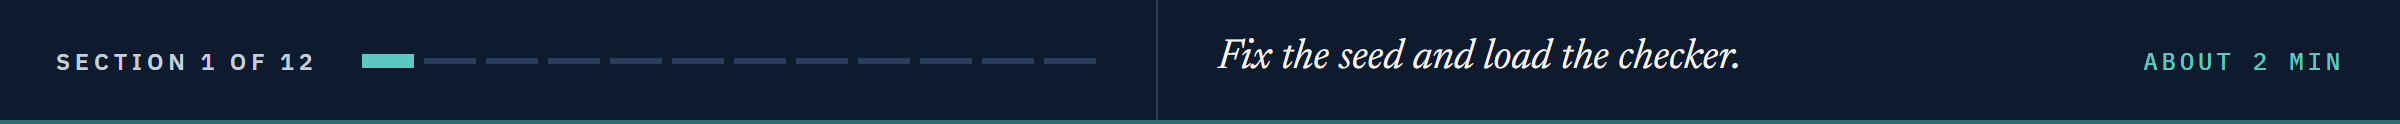

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and the half ellipse of an arc diagram
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Arc

# to split and fold the rows, score by folds, search, and score each row out of fold
from scipy.stats import randint, loguniform
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV

# the steps and the four models, the resampler and its pipeline, recalibration, and SHAP
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.calibration import CalibratedClassifierCV
import shap

# to score flags, rankings and probabilities
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score, brier_score_loss

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# Course 4's colour for each of the four cells of a confusion matrix
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

## The Answer Checker

`check()` compares a fingerprint of each answer with a stored one, so no answer is written on the page.
A number is rounded to the places its question asks for, so you need not round it yourself.

In [3]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written on the page
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ": not attempted yet")
        return
    # a number is rounded to the places the question asks for, so 0.66241 and 0.6624 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + "|" + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have " + str(answer))

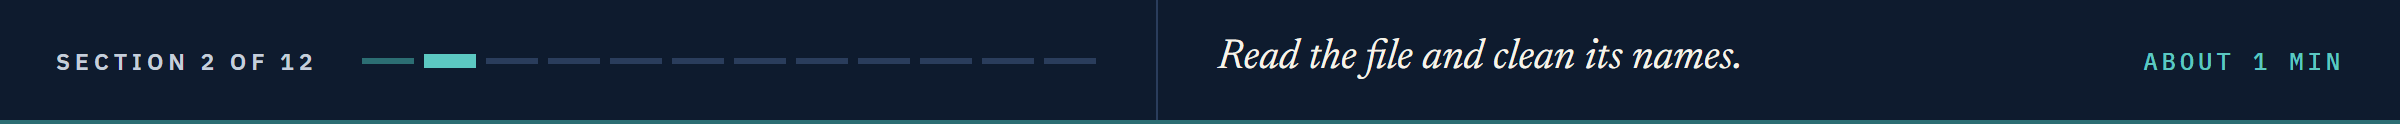

# Loading the Data

## Reading the File and Cleaning the Names

`"\u00a5"` is the yen sign written as an escape, a backslash, `u` and the character's four-digit code, so the cell stays plain ASCII.

In [4]:
# the 6,819 rows: the outcome first, then 95 features whose names start with a space
ratios = pd.read_csv(DATA + "taiwan_bankruptcy.csv")

# each name without its leading space, and without the space and yen sign that end three names
ratios.columns = [name.strip().replace(" \u00a5", "") for name in ratios.columns]
TARGET = "Bankrupt?"
FEATURES = [name for name in ratios.columns if name != TARGET]
print(len(FEATURES), "features; the three cleaned names:", [name for name in FEATURES if "Yuan" in name])

95 features; the three cleaned names: ['Revenue Per Share (Yuan)', 'Operating Profit Per Share (Yuan)', 'Per Share Net profit before tax (Yuan)']


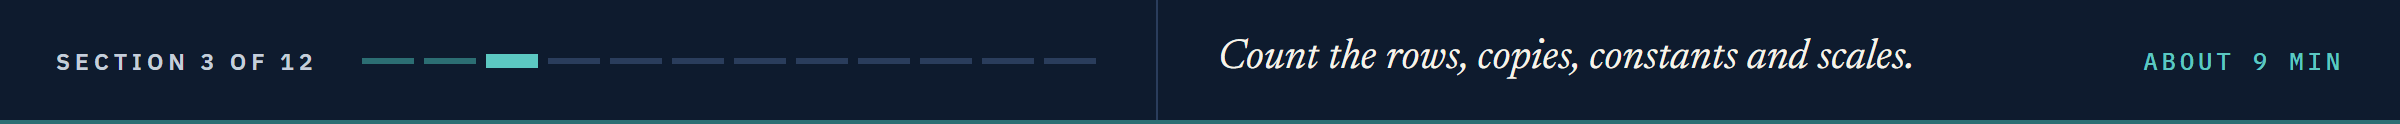

# Data Overview

## Shape, Outcome and Copies

Q. How many rows does the file hold, how many are bankrupt, and what share is that in percent? Store them in `q1_rows`, `q1_bankrupt` and `q1_share` (2 decimals).

In [5]:
# your code here
q1_rows = ...
q1_bankrupt = ...
q1_share = ...

In [6]:
check("Q1 rows", q1_rows, "e0137fa498ca", places=0)
check("Q1 bankrupt rows", q1_bankrupt, "ca66b92568ac", places=0)
check("Q1 bankrupt share", q1_share, "04e9d7ba1266", places=2)

Q1 rows: not attempted yet
Q1 bankrupt rows: not attempted yet
Q1 bankrupt share: not attempted yet


Q. How many cells are empty, and how many rows repeat an earlier row, in full and in the features alone? Store them in `q2_empty`, `q2_copies` and `q2_feature_copies`.

In [7]:
# your code here
q2_empty = ...
q2_copies = ...
q2_feature_copies = ...

In [8]:
check("Q2 empty cells", q2_empty, "d4a945dc91e1", places=0)
check("Q2 copies", q2_copies, "a7d13e02d4bb", places=0)
check("Q2 rows repeating the features", q2_feature_copies, "388d1dc7bb59", places=0)

Q2 empty cells: not attempted yet
Q2 copies: not attempted yet
Q2 rows repeating the features: not attempted yet


## Columns With One or Two Values

Q. Which feature holds one value in every row, and which exactly two? How many rows have the second at 1, and how many of those are bankrupt? Store them in `q3_constant`, `q3_two`, `q3_ones` and `q3_ones_bankrupt`.

In [9]:
# your code here
q3_constant = ...
q3_two = ...
q3_ones = ...
q3_ones_bankrupt = ...

In [10]:
check("Q3 constant feature", q3_constant, "0b578dd697f1")
check("Q3 two-valued feature", q3_two, "a67ae729391f")
check("Q3 rows at 1", q3_ones, "96207b24237e", places=0)
check("Q3 bankrupt rows at 1", q3_ones_bankrupt, "f6d3cb088a0a", places=0)

Q3 constant feature: not attempted yet
Q3 two-valued feature: not attempted yet
Q3 rows at 1: not attempted yet
Q3 bankrupt rows at 1: not attempted yet


## Columns That Repeat

`first.equals(second)` is `True` when two columns hold the same values in every row.

Q. How many pairs of features correlate above 0.99 in absolute value, how many of them are equal in every row, and how many features do they hold? Store them in `q4_near`, `q4_equal` and `q4_columns`.

An **arc diagram** joins related items on a line with arcs.
`Arc((x, 0), width, height, theta1=0, theta2=180)` draws a half ellipse centred at `x`, and `ax.add_patch()` places it.

Q. Draw one for the near pairs, the equal pairs dark.

In [11]:
# your code here
q4_near = ...
q4_equal = ...
q4_columns = ...

# then your chart

In [12]:
check("Q4 pairs above 0.99", q4_near, "553f8b823a65", places=0)
check("Q4 equal pairs", q4_equal, "4a128b55237f", places=0)
check("Q4 features in the pairs", q4_columns, "8a4e8815b180", places=0)

Q4 pairs above 0.99: not attempted yet
Q4 equal pairs: not attempted yet
Q4 features in the pairs: not attempted yet


## Two Scales in One Column

Q. How many features hold a value above 1? How many cells are above 1, and what are the smallest and the largest of them? Store them in `q5_columns`, `q5_cells`, `q5_smallest` and `q5_largest` (0 decimals each).

In [13]:
# your code here
q5_columns = ...
q5_cells = ...
q5_smallest = ...
q5_largest = ...

In [14]:
check("Q5 features above 1", q5_columns, "19f6d584a978", places=0)
check("Q5 cells above 1", q5_cells, "24a37662c656", places=0)
check("Q5 smallest above 1", q5_smallest, "eb4f80c95200", places=0)
check("Q5 largest", q5_largest, "b904ec8ba279", places=0)

Q5 features above 1: not attempted yet
Q5 cells above 1: not attempted yet
Q5 smallest above 1: not attempted yet
Q5 largest: not attempted yet


## Every Value of Those Columns

A **broken axis** splits one axis into two panels with a gap between them, so values far apart sit on one chart.
In the code, `marker=[(-1, -1), (1, 1)]` draws each break mark as a short slash, and `clip_on=False` lets it sit across the panel's edge.

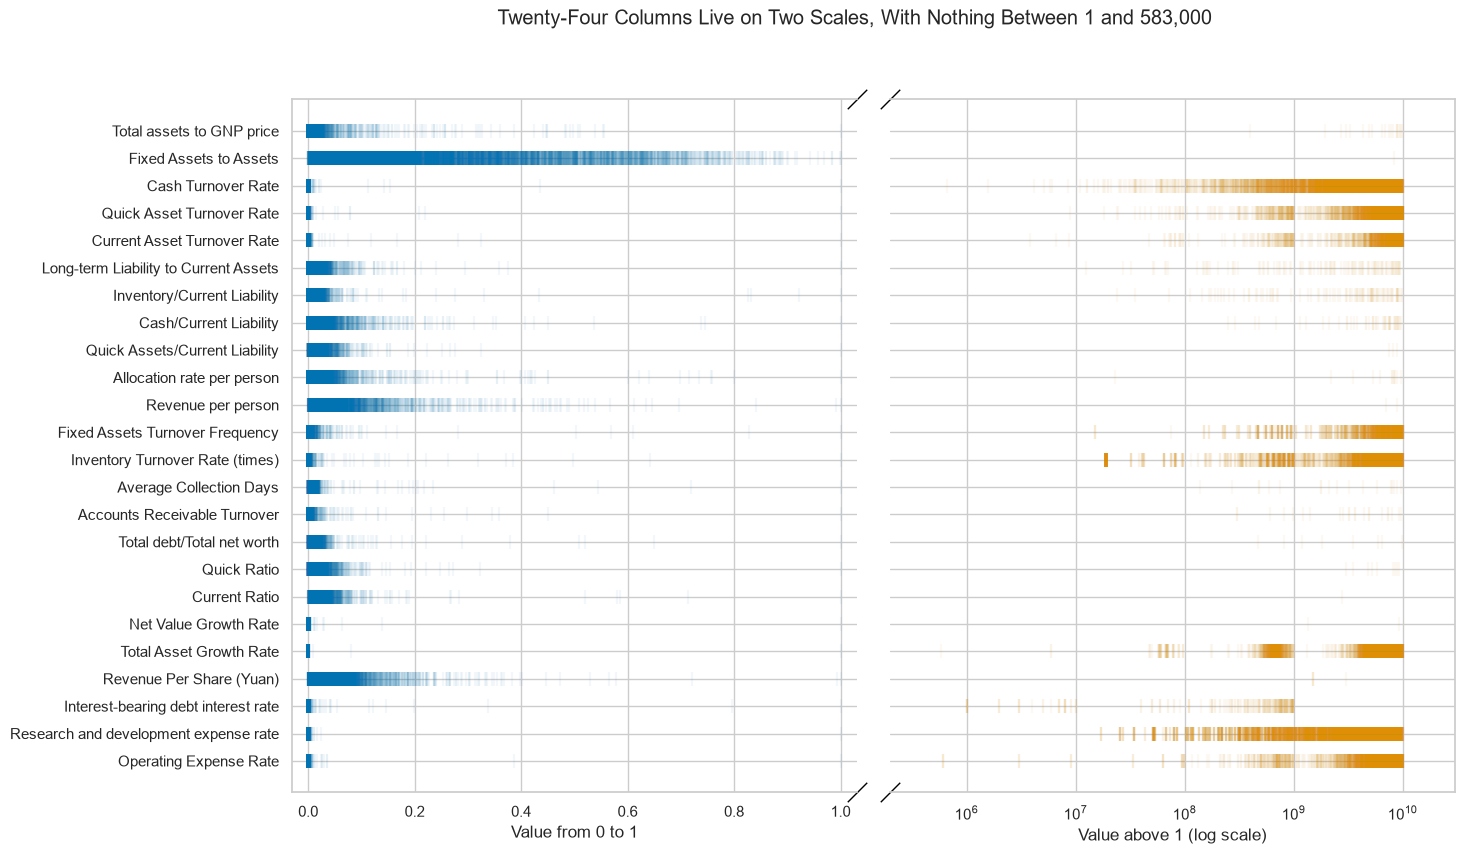

In [15]:
# the columns with a value above 1; each panel draws a column's values as ticks along its own row
wide = [name for name in FEATURES if ratios[name].max() > 1]
fig, (low, high) = plt.subplots(1, 2, sharey=True, figsize=(15, 9))
fig.subplots_adjust(wspace=0.06)  # a narrow gap between the two panels
for row, name in enumerate(wide):
    column = ratios[name]
    low.scatter(column[column <= 1], np.full((column <= 1).sum(), row), marker="|", s=100, alpha=0.05, color="C0")
    high.scatter(column[column > 1], np.full((column > 1).sum(), row), marker="|", s=100, alpha=0.05, color="C1")
low.set(xlim=(-0.03, 1.03), xlabel="Value from 0 to 1")
high.set(xscale="log", xlim=(2e5, 3e10), xlabel="Value above 1 (log scale)")
low.set_yticks(range(len(wide)), wide)
fig.suptitle("Twenty-Four Columns Live on Two Scales, With Nothing Between 1 and 583,000")

# the break: each facing edge hidden, and slashes at its ends (transAxes places a point by the panel's own 0 to 1)
for ax, x, edge in [(low, 1, "right"), (high, 0, "left")]:
    ax.spines[edge].set_visible(False)
    ax.plot([x, x], [0, 1], transform=ax.transAxes, marker=[(-1, -1), (1, 1)], markersize=14, linestyle="none", color="black", clip_on=False)
plt.show()

Most rows sit between 0 and 1, like the other 71 columns; the rest sit from 583,000 to 10 billion.

The page says nothing about the large values, so this notebook describes them and does not guess.

## Does the Scale Say Something?

Q. For `Total Asset Growth Rate` and `Cash Turnover Rate`, what percent of rows is bankrupt above 1, and at or below 1? Keep the four shares, their rows and Course 1's rough margin, 1.96 x sqrt(p x (1 - p) / n), in a table `by_scale`, and store the first column's two shares in `q6_above` and `q6_not` (2 decimals).

Q. Draw the four as dots with their margins as whiskers, the whole file's share dashed.

In [16]:
# your code here
q6_above = ...
q6_not = ...

# then your chart

In [17]:
check("Q6 share above 1", q6_above, "840591e46fcf", places=2)
check("Q6 share at or below 1", q6_not, "5ede3a6627f4", places=2)

Q6 share above 1: not attempted yet
Q6 share at or below 1: not attempted yet


**One constant, two equal pairs and two scales: the preparation drops three columns and learns any list it needs from the training rows.**

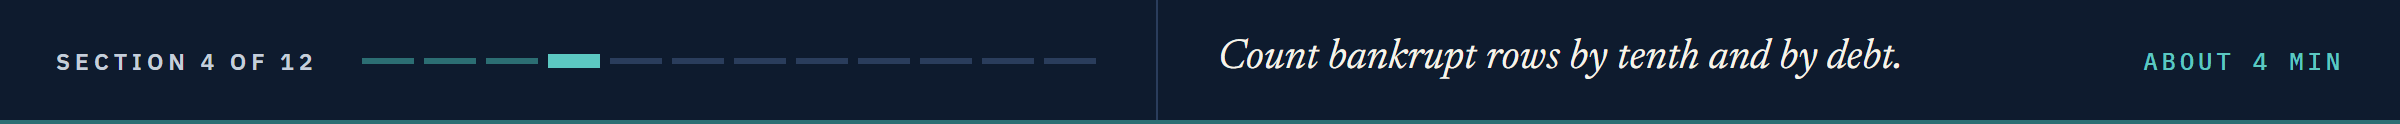

# Exploratory Data Analysis

**Predict 1**

Cut the file into ten slices in its own row order.

If the order meant nothing, each would hold about 22 of the 220 bankrupt rows.

Q. Sketch the ten counts you expect.

## The Order of the File

`np.array_split(values, 10)` cuts an array into ten slices, in order.

Q. Count the bankrupt rows in each tenth as a list of plain numbers (`int(...)` makes one) in `q7_tenths`, and store the position of the first operating row in `q7_first_operating`.

In [18]:
# your code here
q7_tenths = ...
q7_first_operating = ...

In [19]:
check("Q7 bankrupt rows by tenth", q7_tenths, "145cab6ffccc")
check("Q7 first operating row", q7_first_operating, "ff63aa731dc3", places=0)

Q7 bankrupt rows by tenth: not attempted yet
Q7 first operating row: not attempted yet


## The Bankrupt Rows Along the File

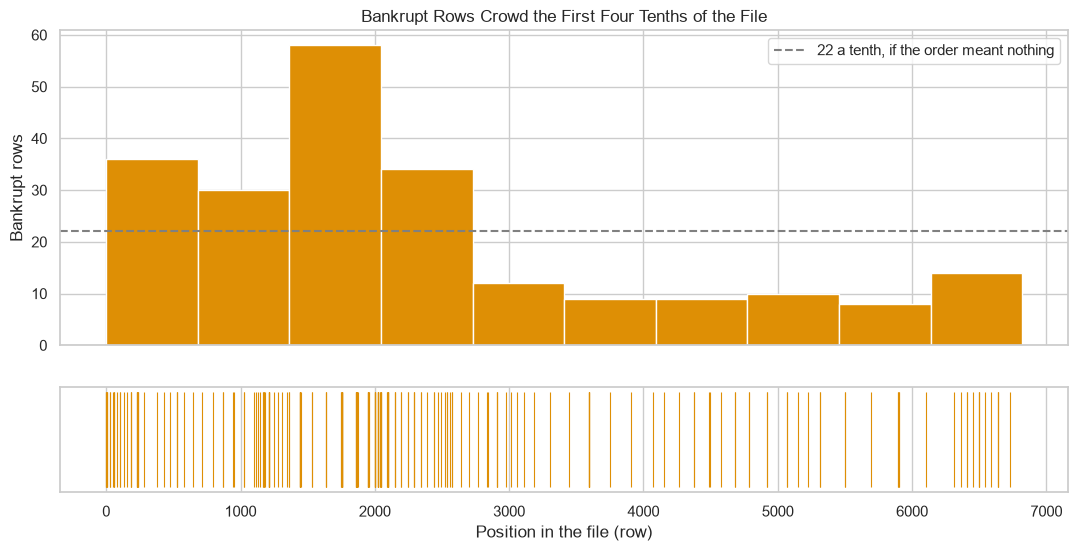

In [20]:
# the bankrupt rows per tenth as bars over the file's positions, and each bankrupt row as a tick underneath
edges = np.linspace(0, len(ratios), 11)
tenths = [piece.sum() for piece in np.array_split(ratios[TARGET].to_numpy(), 10)]
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(13, 6), height_ratios=[3, 1])
top.bar(edges[:-1], tenths, width=np.diff(edges), align="edge", color="C1", edgecolor="white")
top.axhline(22, color="gray", linestyle="--", label="22 a tenth, if the order meant nothing")
top.set(ylabel="Bankrupt rows", title="Bankrupt Rows Crowd the First Four Tenths of the File")
top.legend(loc="upper right")
bottom.vlines(ratios.index[ratios[TARGET] == 1], 0, 1, color="C1", linewidth=0.8)
bottom.set(yticks=[], xlabel="Position in the file (row)")
plt.show()

158 of the 220 sit in the first four tenths, and the first six rows are all bankrupt.

A split in file order would give the test rows another bankrupt share, so the split is shuffled and stratified, and position is never a feature.

## Debt by Outcome

Q. What is the median `Debt ratio %` of the bankrupt rows, and of the others? Store them in `q8_bankrupt` and `q8_operating` (4 decimals).

Q. Draw each outcome's `Debt ratio %` as an ECDF (Course 4's Day 6).

In [21]:
# your code here
q8_bankrupt = ...
q8_operating = ...

# then your chart

In [22]:
check("Q8 median, bankrupt", q8_bankrupt, "8ef7dd720f31", places=4)
check("Q8 median, operating", q8_operating, "100833c0f5c8", places=4)

Q8 median, bankrupt: not attempted yet
Q8 median, operating: not attempted yet


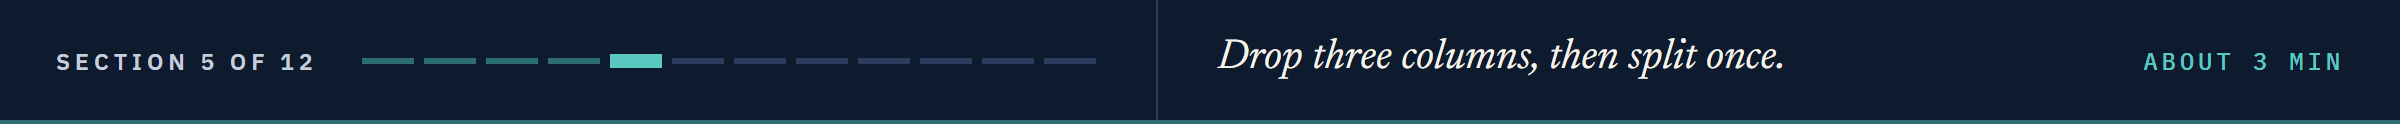

# Data Preparation for Modeling

## Three Columns Out, Then One Split

Q. Drop the constant and the second feature of each equal pair, then split 80/20 into `X_train, X_test, y_train, y_test` with `stratify=y` and the course seed. Store the features left, the training rows and the training bankruptcies in `q9_features`, `q9_train_rows` and `q9_train_bankrupt`.

In [23]:
# your code here
q9_features = ...
q9_train_rows = ...
q9_train_bankrupt = ...

In [24]:
check("Q9 features", q9_features, "4b7385b8a143", places=0)
check("Q9 training rows", q9_train_rows, "b3e54af21628", places=0)
check("Q9 training bankruptcies", q9_train_bankrupt, "7b166db90baa", places=0)

Q9 features: not attempted yet
Q9 training rows: not attempted yet
Q9 training bankruptcies: not attempted yet


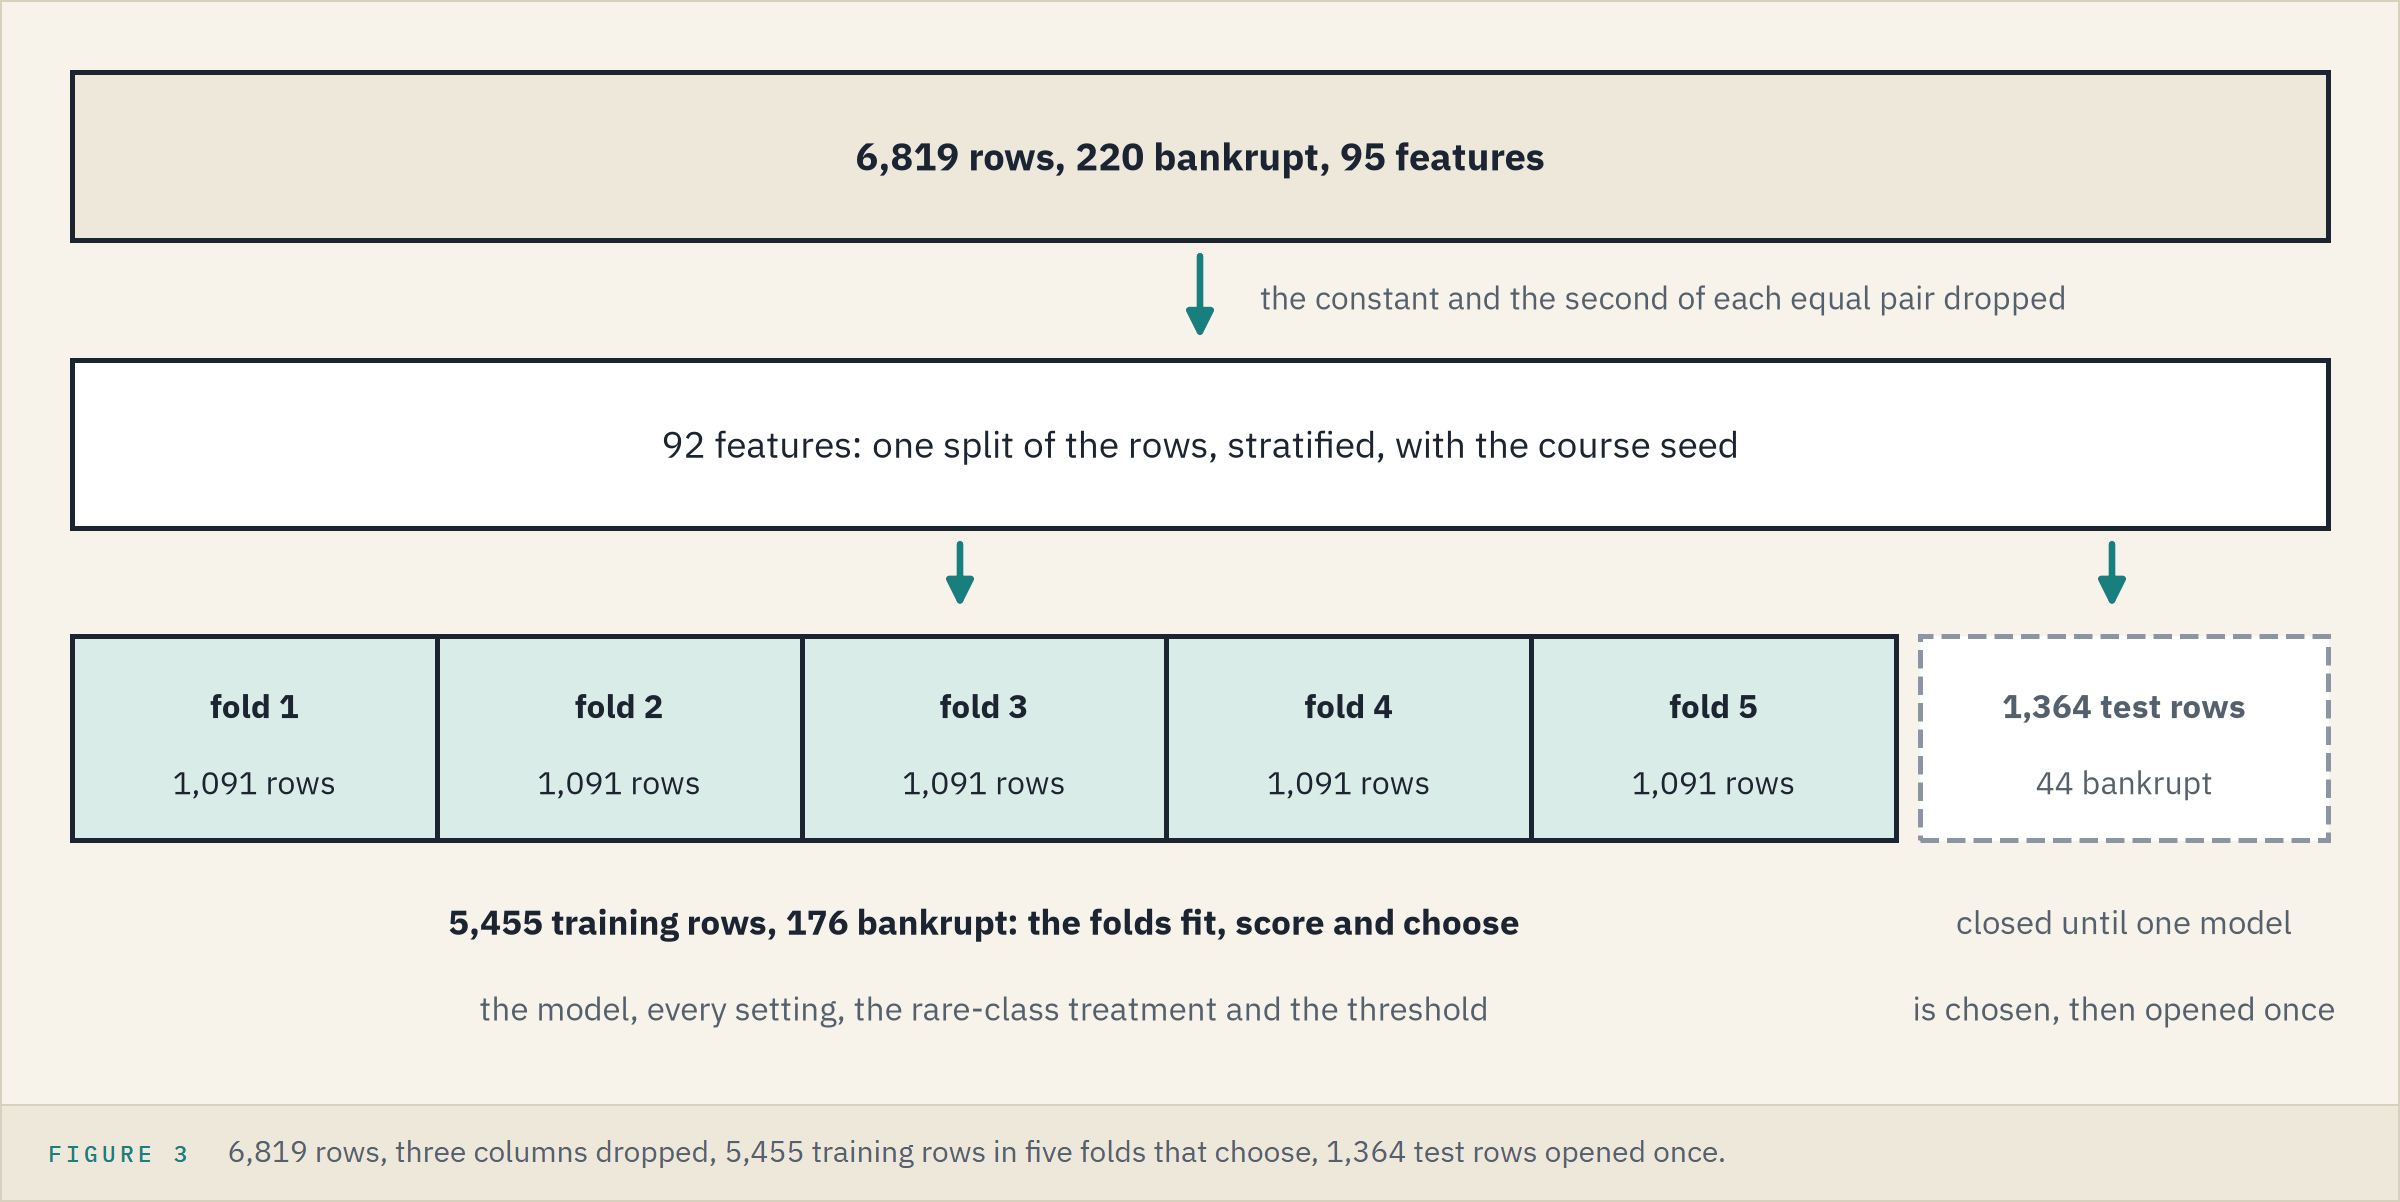

**Every choice from here is made on the 5,455 training rows.**

## The Two-Scale List, From Training Rows

Q. Keep the features above 1 in the training rows in a list `two_scale`. Store how many in `q10_count`, and the one feature of the whole file's list missing from it in `q10_missing`.

In [25]:
# your code here
q10_count = ...
q10_missing = ...

In [26]:
check("Q10 two-scale features", q10_count, "4bfd491865c4", places=0)
check("Q10 the feature missing", q10_missing, "abb8175dc22c")

Q10 two-scale features: not attempted yet
Q10 the feature missing: not attempted yet


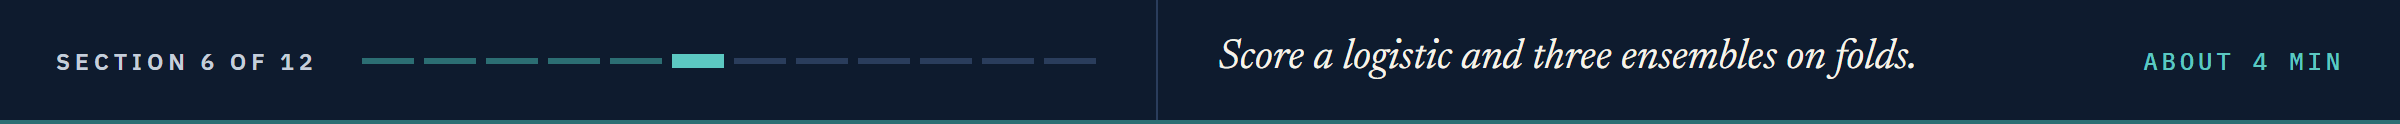

# Model Building

## Model Evaluation Criterion

Flagging nobody is right about 97 percent of the time.

So models are ranked by **average precision** on five folds of the training rows (Course 4's capstone), ROC AUC beside it; a random ranking scores about 0.03.

Each gets a threshold for a recall of 0.70, the desk's illustration.

## The Folds and the Scoring Functions

Course 4's capstone scoring function with average precision first, and Day 10's threshold for a recall.

In [27]:
# five stratified folds of the training rows, shuffled with the course seed (Day 11's)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# flag at or above the threshold, then average precision, ROC AUC and four measures in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "Average precision": [average_precision_score(target, model.predict_proba(predictors)[:, 1])],
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

# the highest threshold whose recall on these outputs is at least the target
def threshold_for_recall(target, output, target_recall=0.70):
    precision, recall, thresholds = precision_recall_curve(target, output)
    return thresholds[recall[:-1] >= target_recall].max()

## Course 4's Logistic, Without Its Weights

Course 4's capstone logistic, without its imputer (no gaps here) or its class weights (Day 13 found the unweighted logistic ranks better).

Q. Build `logistic`, a pipeline of `QuantileTransformer(output_distribution="normal", random_state=SEED)` and `LogisticRegression(solver="newton-cholesky", tol=1e-8)` (steps `"quantile"`, `"logit"`), and score it with `cross_validate` on `folds`, scoring `["average_precision", "roc_auc"]`. Store the mean scores in `q11_ap` and `q11_auc` (4 decimals).

In [28]:
# your code here
q11_ap = ...
q11_auc = ...

In [29]:
check("Q11 fold average precision", q11_ap, "bbb51b3dfc01", places=4)
check("Q11 fold ROC AUC", q11_auc, "944e1994707d", places=4)

Q11 fold average precision: not attempted yet
Q11 fold ROC AUC: not attempted yet


## Three Ensembles

To keep the run short, only the leader will be searched.

Q. Put four models in a dictionary `models` under `"logistic"`, `"forest"` (Day 3's random forest, here 100 trees with leaves of 5 rows or more), `"xgboost"` (XGBoost with two of Day 8's brakes, depth 3 and a step of 0.05, over 300 trees) and `"lightgbm"` (Day 11's LightGBM at its defaults), each with the seed and `n_jobs=1`. Keep each fold's average precision in a table `fold_ap`, one column per model. Store the ensembles' means in `q12_forest`, `q12_xgboost` and `q12_lightgbm` (4 decimals), and the folds where LightGBM beats the logistic in `q12_folds`.

Q. Draw each fold as a line across the models, the means in bold.

In [30]:
# your code here
q12_forest = ...
q12_xgboost = ...
q12_lightgbm = ...
q12_folds = ...

# then your chart

In [31]:
check("Q12 forest", q12_forest, "cfb35f5e18e5", places=4)
check("Q12 XGBoost", q12_xgboost, "c806a55d8aa6", places=4)
check("Q12 LightGBM", q12_lightgbm, "8501a9215b44", places=4)
check("Q12 folds LightGBM beats the logistic", q12_folds, "af6bb19bdcf8", places=0)

Q12 forest: not attempted yet
Q12 XGBoost: not attempted yet
Q12 LightGBM: not attempted yet
Q12 folds LightGBM beats the logistic: not attempted yet


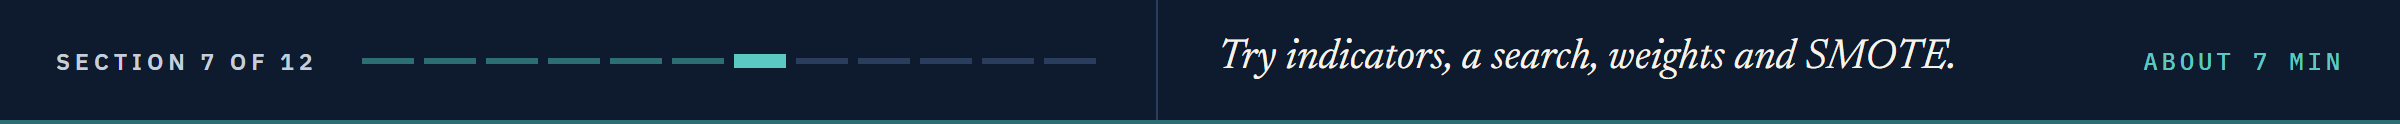

# Model Performance Improvement

## Indicators for the Two Scales

Q. Write `add_above_one(frame)`, returning the frame plus a 0/1 column per feature in `two_scale`, 1 above 1. Put it in Day 12's `FunctionTransformer` as step `"above"` before the logistic's two steps, and score it on `folds`. Store its mean in `q13_ap` (4 decimals) and the folds where it beats the logistic in `q13_folds`.

In [32]:
# your code here
q13_ap = ...
q13_folds = ...

In [33]:
check("Q13 fold average precision", q13_ap, "69bdff75f4fc", places=4)
check("Q13 folds it beats the logistic", q13_folds, "c4972029744c", places=0)

Q13 fold average precision: not attempted yet
Q13 folds it beats the logistic: not attempted yet


## A Random Search for LightGBM

Q. Search Day 11's space for `models["lightgbm"]` (`num_leaves` from `randint(8, 32)`, `learning_rate` from `loguniform(0.03, 0.3)`) with `RandomizedSearchCV(..., n_iter=6, scoring="average_precision", cv=folds, random_state=SEED, n_jobs=1)`, as `search`. Store the best leaves, rate and `best_score_` in `q14_leaves`, `q14_rate` and `q14_best` (4 decimals).

Q. Draw Day 11's search-space scatter, the defaults (31 leaves, 0.1) as a cross.

In [34]:
# your code here
q14_leaves = ...
q14_rate = ...
q14_best = ...

# then your chart

In [35]:
check("Q14 best leaves", q14_leaves, "4190ce351f8e", places=0)
check("Q14 best rate", q14_rate, "ad1ff9205f0c", places=4)
check("Q14 best fold score", q14_best, "5ebf38c2701d", places=4)

Q14 best leaves: not attempted yet
Q14 best rate: not attempted yet
Q14 best fold score: not attempted yet


**Predict 2**

The search's best scores 0.4834 on the folds that chose it, and the defaults 0.4785.

Q. Run the whole search inside each fold, as Day 11 did, and score each winner on the fold it never saw. What will the mean be? Write down a number.

## The Search, Scored Honestly

Q. Score `inner_search`, the same search on `StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)`, with Day 11's nested `cross_validate(..., cv=folds, return_estimator=True, n_jobs=1)`. Store the outer mean in `q15_nested` (4 decimals) and the number of different winners in `q15_winners`.

In [36]:
# your code here
q15_nested = ...
q15_winners = ...

In [37]:
check("Q15 nested score", q15_nested, "70214d3e8f86", places=4)
check("Q15 different winners", q15_winners, "14d8a905a382", places=0)

Q15 nested score: not attempted yet
Q15 different winners: not attempted yet


## Weights, SMOTE, or Neither

Q. Score LightGBM two more ways on `folds`, both Day 13's: `class_weight="balanced"`, and `SMOTE(random_state=SEED)` before it in an `ImbPipeline` (steps `"smote"`, `"lightgbm"`). Keep the three versions in `versions` (`"neither"`, `"balanced"`, `"smote"`) and their fold scores in a table `version_ap`. Store the new means in `q16_balanced` and `q16_smote` (4 decimals).

Q. Draw the means as bars, the fold scores as dots.

In [38]:
# your code here
q16_balanced = ...
q16_smote = ...

# then your chart

In [39]:
check("Q16 balanced", q16_balanced, "e125211f8f65", places=4)
check("Q16 SMOTE", q16_smote, "db6fdca3b391", places=4)

Q16 balanced: not attempted yet
Q16 SMOTE: not attempted yet


Q. Score each version out of fold with `cross_val_predict(..., method="predict_proba")` and read its threshold for a recall of 0.70. In a table `at_70`, give each its threshold, rows flagged, their precision and its mean output, and store the flags in `q17_neither`, `q17_balanced` and `q17_smote`.

In [40]:
# your code here
q17_neither = ...
q17_balanced = ...
q17_smote = ...

In [41]:
check("Q17 flagged, neither", q17_neither, "fd564570a727", places=0)
check("Q17 flagged, balanced", q17_balanced, "d20469d99c08", places=0)
check("Q17 flagged, SMOTE", q17_smote, "8ed29cd42134", places=0)

Q17 flagged, neither: not attempted yet
Q17 flagged, balanced: not attempted yet
Q17 flagged, SMOTE: not attempted yet


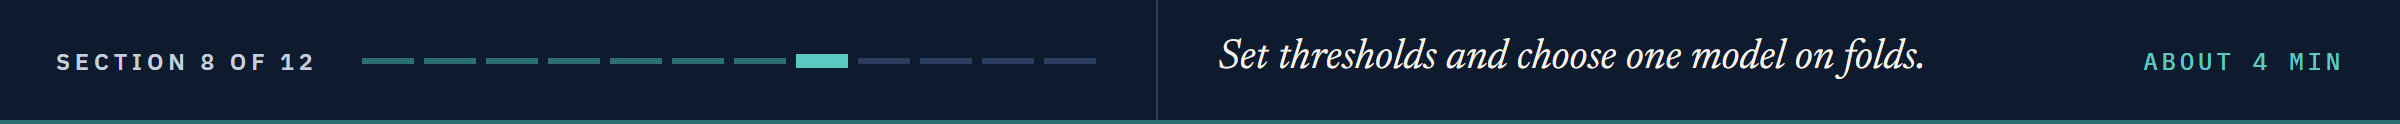

# Final Model Selection

The criterion was set before any model was fitted: fold average precision first.

## Thresholds for a Recall of 0.70

Q. Keep the four models' out-of-fold outputs in a dictionary `out_of_fold` (LightGBM's are `outputs["neither"]`) and their thresholds for 0.70 in `thresholds`. Store the logistic's, forest's and XGBoost's in `q18_logistic`, `q18_forest` and `q18_xgboost` (4 decimals).

Q. Draw the four out-of-fold precision-recall curves, recall 0.70 dashed, each threshold a dot.

In [42]:
# your code here
q18_logistic = ...
q18_forest = ...
q18_xgboost = ...

# then your chart

In [43]:
check("Q18 logistic threshold", q18_logistic, "e9a3d18701ae", places=4)
check("Q18 forest threshold", q18_forest, "c90ab6c70f60", places=4)
check("Q18 XGBoost threshold", q18_xgboost, "796b227db313", places=4)

Q18 logistic threshold: not attempted yet
Q18 forest threshold: not attempted yet
Q18 XGBoost threshold: not attempted yet


## Judged on Their Own Rows

Q. Fit each model on all the training rows and score it there. Set that score beside its fold mean in a table `gap_table`, and store LightGBM's and the logistic's in `q19_lightgbm` and `q19_logistic` (4 decimals).

Q. Draw each model as a dumbbell from its fold mean to its training-row score.

In [44]:
# your code here
q19_lightgbm = ...
q19_logistic = ...

# then your chart

In [45]:
check("Q19 LightGBM on its own rows", q19_lightgbm, "413880f26e99", places=4)
check("Q19 logistic on its own rows", q19_logistic, "5bf4b8f51dc4", places=4)

Q19 LightGBM on its own rows: not attempted yet
Q19 logistic on its own rows: not attempted yet


## The Choice

Q. Which model goes forward, by the criterion set before any model was fitted? Store its key in `models` in `q20_choice`, and write one reason a line.

In [46]:
# your code here
q20_choice = ...

In [47]:
check("Q20 the choice", q20_choice, "9d9041d8ad05")

Q20 the choice: not attempted yet


**One model goes forward, chosen before one test row is scored.**

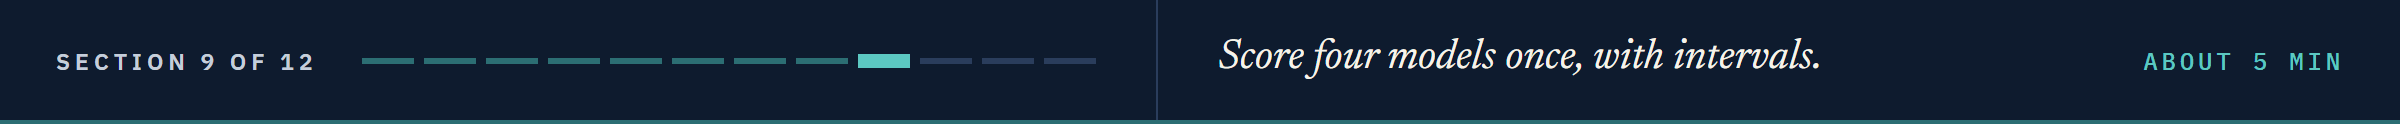

# The Test Rows, Opened Once

**Predict 3**

Out of fold, LightGBM's threshold of 0.0039 catches 124 of the 176 training bankruptcies, 70.5 percent.

Q. How many of the 44 test bankruptcies will it flag?

**Predict 4**

Q. Which of the four models will have the highest average precision on the test rows, and what will it be? Write down a name and a number.

## The Test Table

Q. Score the four models on the test rows in one table `test_comp`, each at its threshold, and keep their test outputs in a dictionary `test_outputs`. Store LightGBM's test bankruptcies flagged and test average precision in `q21_caught` and `q21_ap` (4 decimals), and the key of the model highest on test average precision in `q21_best`.

Q. Draw the four confusion matrices in Course 4's colours.

In [48]:
# your code here
q21_caught = ...
q21_ap = ...
q21_best = ...

# then your chart

In [49]:
check("Q21 test bankruptcies flagged", q21_caught, "2d82ca9df415", places=0)
check("Q21 test average precision", q21_ap, "eb5dde24d64a", places=4)
check("Q21 highest on the test rows", q21_best, "1f19067b48f6")

Q21 test bankruptcies flagged: not attempted yet
Q21 test average precision: not attempted yet
Q21 highest on the test rows: not attempted yet


**Predict 5**

On 6,000 card accounts with 1,327 defaults, Day 10's intervals were about 0.028 wide on ROC AUC and 0.059 on average precision (its Exercise 2).

Q. Resample the 1,364 test rows 1,000 times. How wide will the 95 percent interval of LightGBM's test average precision be? Write down a number.

## How Sure Can Anyone Be?

Q. With Day 10's `rng = np.random.default_rng(SEED)` and `draws = rng.choice(1364, size=(1000, 1364))`, score each model's test average precision on every resample, in a table `boot_ap`. Store LightGBM's 95 percent interval in `q22_low` and `q22_high`, and that of LightGBM minus the logistic, paired, in `q22_pair_low` and `q22_pair_high` (4 decimals).

An **estimation plot** sets each score with its interval beside each paired difference with its interval, against zero.

Q. Draw one, with the test scores, their intervals and the fold means as rings on the left, and LightGBM minus each model as a half violin with its interval as a bar on the right.

In [50]:
# your code here
q22_low = ...
q22_high = ...
q22_pair_low = ...
q22_pair_high = ...

# then your chart

In [51]:
check("Q22 LightGBM low", q22_low, "88c13afdaf94", places=4)
check("Q22 LightGBM high", q22_high, "e2bf2001901d", places=4)
check("Q22 paired low", q22_pair_low, "43c03d1852f7", places=4)
check("Q22 paired high", q22_pair_high, "c242294b68c0", places=4)

Q22 LightGBM low: not attempted yet
Q22 LightGBM high: not attempted yet
Q22 paired low: not attempted yet
Q22 paired high: not attempted yet


## Which Bankruptcies Each Model Catches

Q. For each test bankruptcy, note which models flag it, in a table `caught`, one column per model. Store how many all four flag and how many none flags in `q23_all` and `q23_none`.

In [52]:
# your code here
q23_all = ...
q23_none = ...

In [53]:
check("Q23 caught by all four", q23_all, "3789e3ae8563", places=0)
check("Q23 caught by none", q23_none, "c47017325a12", places=0)

Q23 caught by all four: not attempted yet
Q23 caught by none: not attempted yet


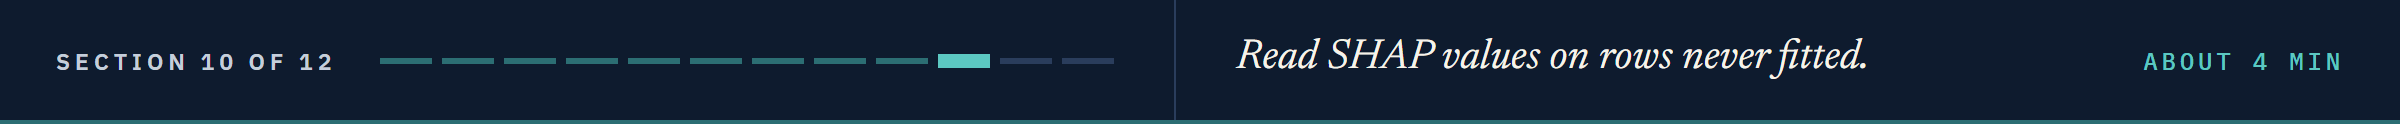

# What the Model Leans On

Day 14 found that SHAP values on fitted rows describe memory, so the chosen model is described on the 1,364 test rows it never fitted.
A SHAP value is a contribution to a row's log-odds relative to the model's average, never a reason.

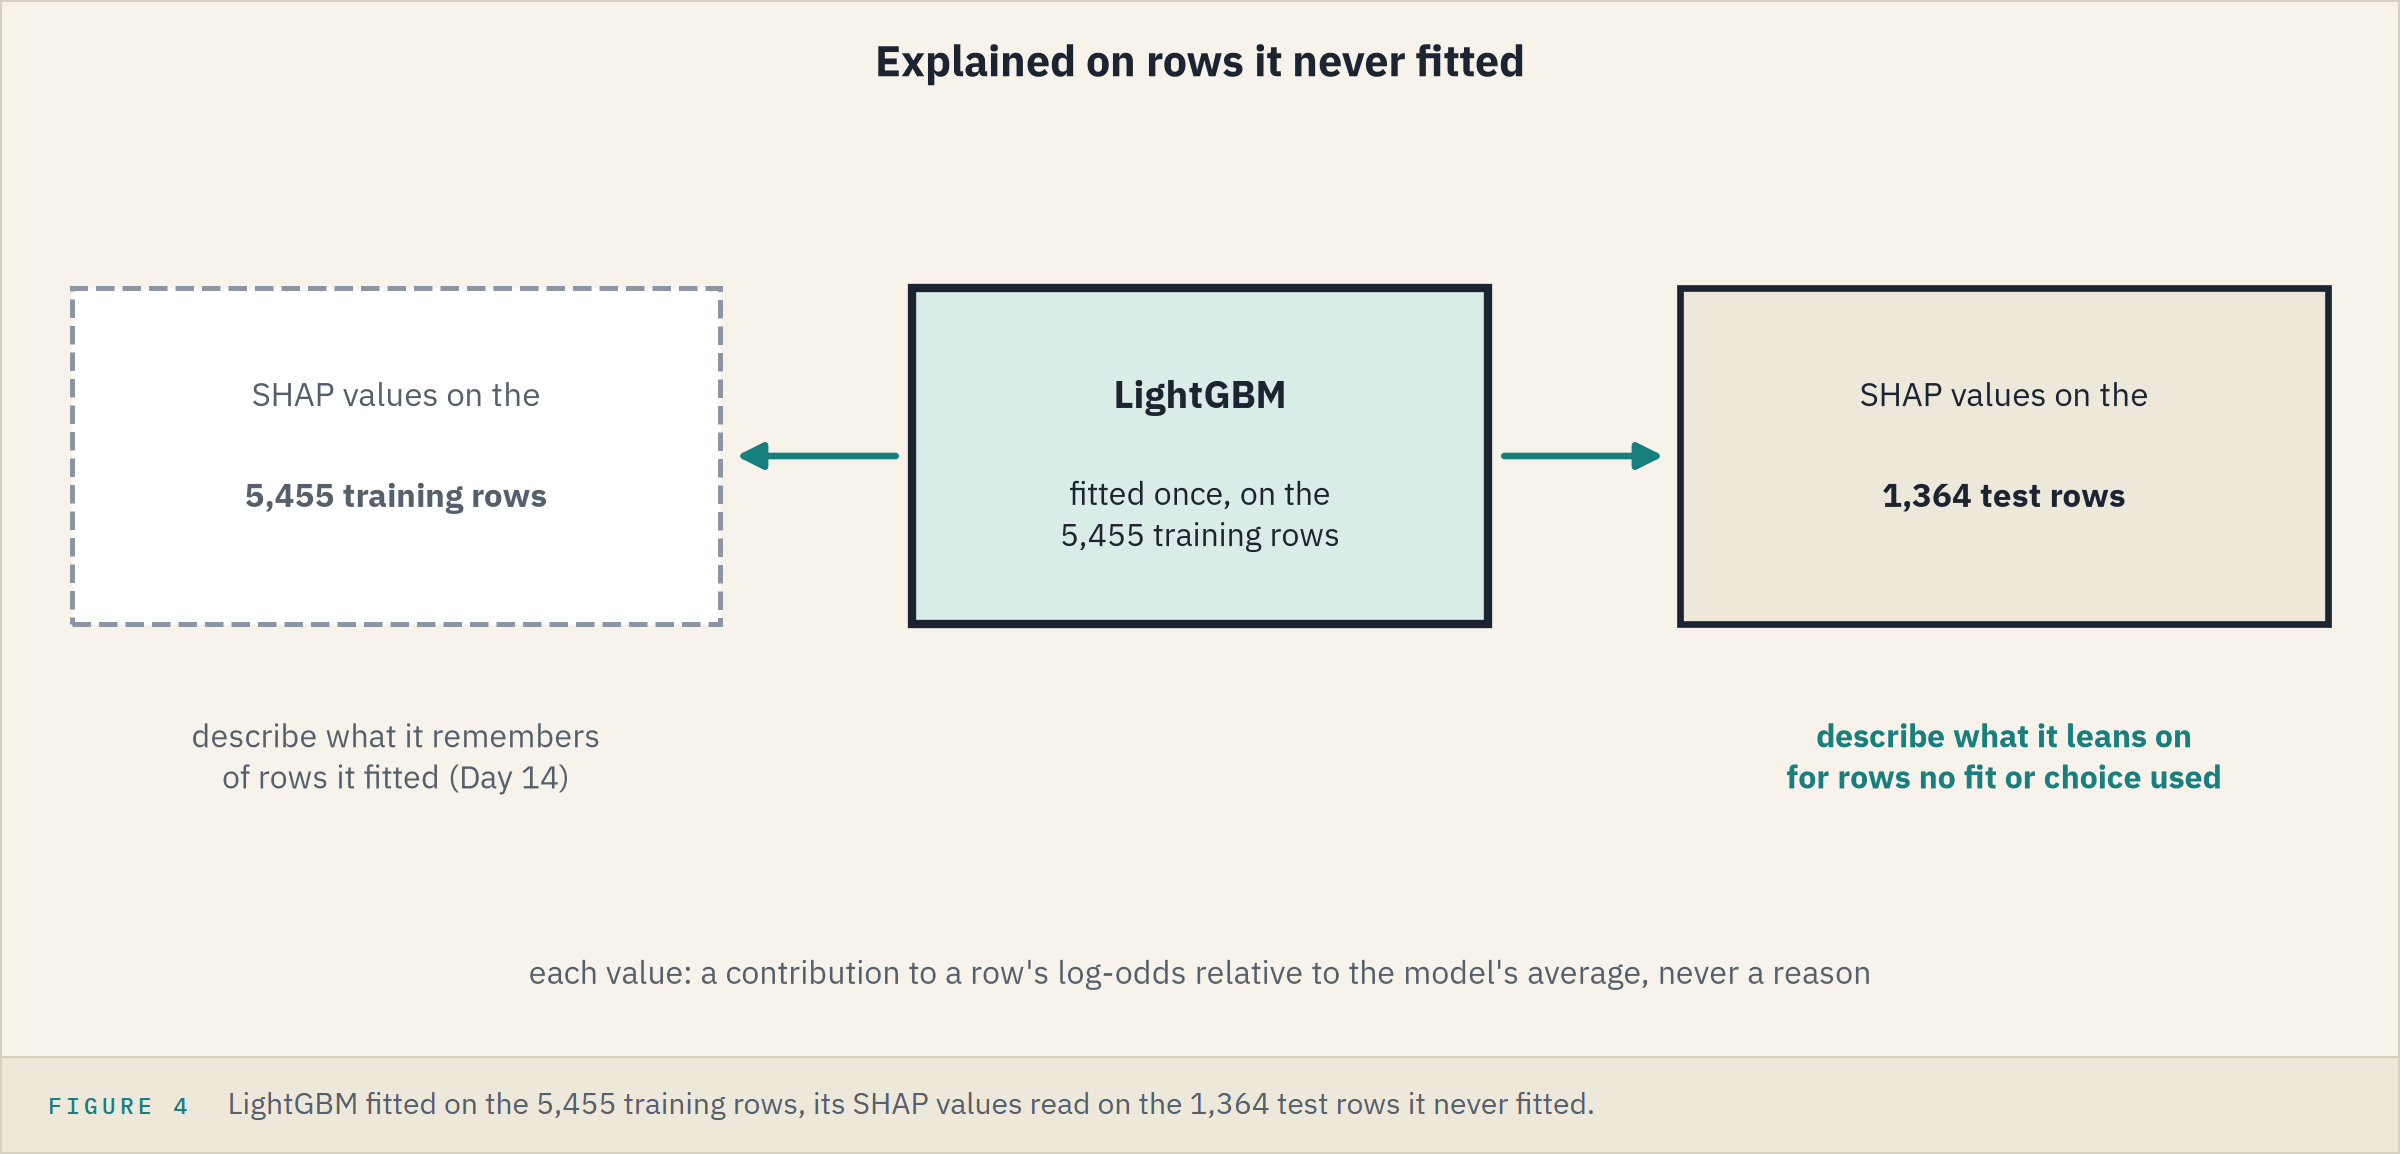

## SHAP Values on the Test Rows

Q. Explain the fitted LightGBM on `X_test` with Day 14's `shap.TreeExplainer`, as `shap_test`. Store the base value in `q24_base` (4 decimals), the feature with the largest mean absolute SHAP value and that value in `q24_top` and `q24_top_value` (4 decimals), and how many of the test rows' top ten are also top ten on the training rows in `q24_shared`.

Q. Draw the beeswarm of the top ten with `shap.summary_plot(..., max_display=10, rng=SEED, show=False)`.

In [54]:
# your code here
q24_base = ...
q24_top = ...
q24_top_value = ...
q24_shared = ...

# then your chart

In [55]:
check("Q24 base value", q24_base, "df66450a246e", places=4)
check("Q24 top feature", q24_top, "41152d38bd47")
check("Q24 its mean absolute SHAP value", q24_top_value, "ff6011615fb0", places=4)
check("Q24 shared in the top ten", q24_shared, "e5ab4286fa2b", places=0)

Q24 base value: not attempted yet
Q24 top feature: not attempted yet
Q24 its mean absolute SHAP value: not attempted yet
Q24 shared in the top ten: not attempted yet


## Split Counts Against SHAP

Q. Keep LightGBM's split counts, Day 9's `booster_.feature_importance("split")`, in a Series `splits`. How many of the split top ten and of the SHAP top ten are in `two_scale`? Store them in `q25_split_two_scale` and `q25_shap_two_scale`, and the most split feature in `q25_top_split`.

Q. Draw a slopegraph from rank by split count to rank by mean absolute SHAP value for the features in either top ten, two-scale features in colour.

In [56]:
# your code here
q25_split_two_scale = ...
q25_shap_two_scale = ...
q25_top_split = ...

# then your chart

In [57]:
check("Q25 two-scale in the split top ten", q25_split_two_scale, "484ebff6fdbd", places=0)
check("Q25 two-scale in the SHAP top ten", q25_shap_two_scale, "91ff364ccd0c", places=0)
check("Q25 most split feature", q25_top_split, "a4fd9d831b88")

Q25 two-scale in the split top ten: not attempted yet
Q25 two-scale in the SHAP top ten: not attempted yet
Q25 most split feature: not attempted yet


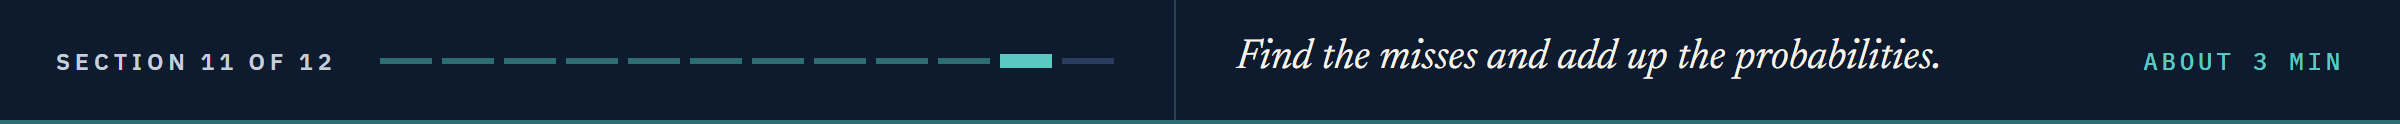

# Where the Model Fails

## The Misses

Q. Which test bankruptcies does LightGBM miss at its threshold? Store how many, the highest probability among them (5 decimals) and its row label in `q26_missed`, `q26_highest` and `q26_row`, and compare the median `Total debt/Total net worth` of the missed, caught and operating test rows.

Q. Draw that row's waterfall (Day 14).

In [58]:
# your code here
q26_missed = ...
q26_highest = ...
q26_row = ...

# then your chart

In [59]:
check("Q26 missed", q26_missed, "4cfb7a5305bd", places=0)
check("Q26 highest probability missed", q26_highest, "0324e0f45276", places=5)
check("Q26 its row", q26_row, "0b569c54a2b3", places=0)

Q26 missed: not attempted yet
Q26 highest probability missed: not attempted yet
Q26 its row: not attempted yet


## What the Probabilities Add Up To

Q. Add up LightGBM's out-of-fold probabilities on the training rows, and its probabilities on the test rows. Store the sums in `q27_oof` and `q27_test` (1 decimal), against 176 and 44 bankruptcies.

In [60]:
# your code here
q27_oof = ...
q27_test = ...

In [61]:
check("Q27 out-of-fold sum", q27_oof, "326a8909b574", places=1)
check("Q27 test sum", q27_test, "77d60f04e03c", places=1)

Q27 out-of-fold sum: not attempted yet
Q27 test sum: not attempted yet


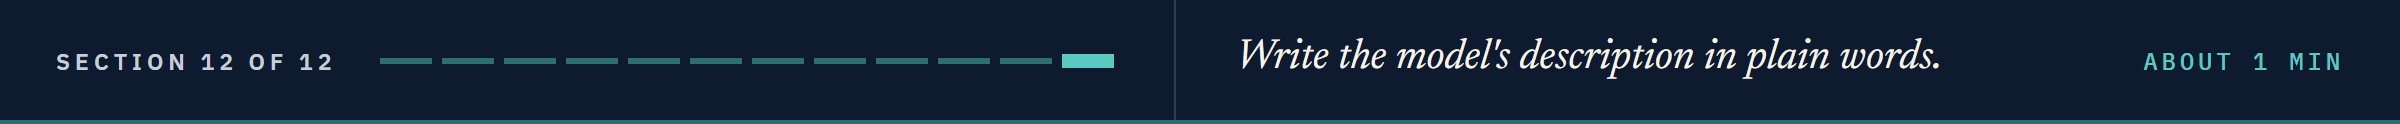

# Insights and Conclusion

## The Description

Q. Write `description`, a few sentences in one string: how well the chosen model ranks the test rows and how sure anyone can be, where it is wrong, what the data cannot support, and what was not tested.

In [62]:
# your code here
description = ...

**A model describes the file it was fitted on.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Describe a new file's constants, copies, near-copies and scales before any model sees it.
* Compare models on folds and score a search with nested cross-validation.
* Choose class weights, resampling and a threshold from out-of-fold outputs.
* Open the test rows once and put an interval, paired or not, on each score.
* Describe a model with SHAP values on rows it never fitted.

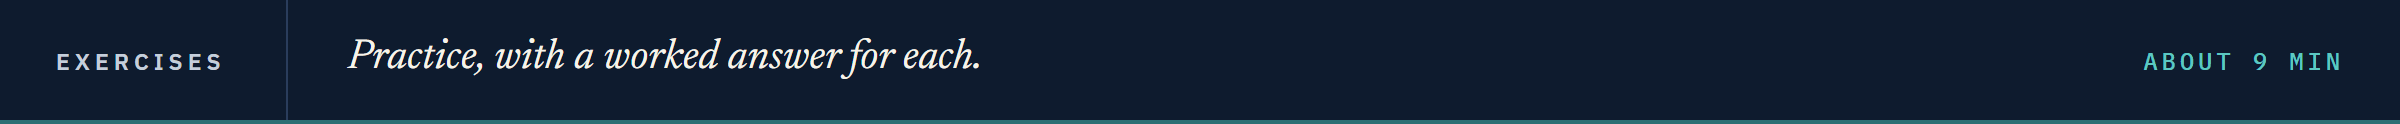

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

`check()` from Setting Up marks each answer.

### Exercise 1

**A Recall Target of 0.80**

Q. Read LightGBM's out-of-fold threshold for a recall of 0.80 with `threshold_for_recall`, and count the training rows it flags. Store them in `ex1_threshold` (4 decimals) and `ex1_flagged`.

In [63]:
# your code here
ex1_threshold = ...
ex1_flagged = ...

In [64]:
check("Exercise 1 threshold", ex1_threshold, "9e4f6222d1cf", places=4)
check("Exercise 1 flagged", ex1_flagged, "e6d1cb81787c", places=0)

Exercise 1 threshold: not attempted yet
Exercise 1 flagged: not attempted yet


### Exercise 2

**Probabilities That Add Up**

Q. Score Day 13's `CalibratedClassifierCV(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1), method="isotonic", cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), n_jobs=1)` out of fold on `folds`. Store the sum of its probabilities (1 decimal) and its Brier score (4 decimals) in `ex2_sum` and `ex2_brier`.

In [65]:
# your code here
ex2_sum = ...
ex2_brier = ...

In [66]:
check("Exercise 2 sum", ex2_sum, "b162cf9fad0c", places=1)
check("Exercise 2 Brier score", ex2_brier, "36552865f46e", places=4)

Exercise 2 sum: not attempted yet
Exercise 2 Brier score: not attempted yet


### Exercise 3: AI check

**The File's Own Order**

You asked an AI assistant for a function that splits the rows 80/20.
This came back.
It runs, and its comment sounds careful.
Test it, then find the one bug.

In [67]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def split_rows(frame):
    # split 80/20 and keep the file's order, so the split is the same on every run
    return train_test_split(frame[FEATURES], frame[TARGET], test_size=0.2, shuffle=False)

In [68]:
# the test: the test rows' bankrupt share must sit within 0.25 percentage points of the whole file's
ai_train, ai_test, ai_y_train, ai_y_test = split_rows(ratios)
test_share, file_share = ai_y_test.mean() * 100, ratios[TARGET].mean() * 100
assert abs(test_share - file_share) < 0.25, f"the test rows are {test_share:.2f} percent bankrupt against {file_share:.2f} in the file"

AssertionError: the test rows are 1.61 percent bankrupt against 3.23 in the file

Q. Fix the function: shuffle, stratify on the outcome and use the course seed. Store the bankrupt share of its test rows, in percent, in `ex3_share` (2 decimals).

In [69]:
# your code here
ex3_share = ...

In [70]:
check("Exercise 3 test share", ex3_share, "de80c5eaf100", places=2)

Exercise 3 test share: not attempted yet


## Congratulations!

You ran the whole course on a file nobody had shown you, and the work was yours.
You found a constant, copied pairs, two scales and an order that carries the outcome, and kept the test rows closed through it all.
You chose every setting on folds, opened the test rows once, and gave the interval as the honest answer.
Course 5B turns to dated series, starting with the gaps in Treasury yields, and Course 6's capstone brings these 5,455 training rows back.

[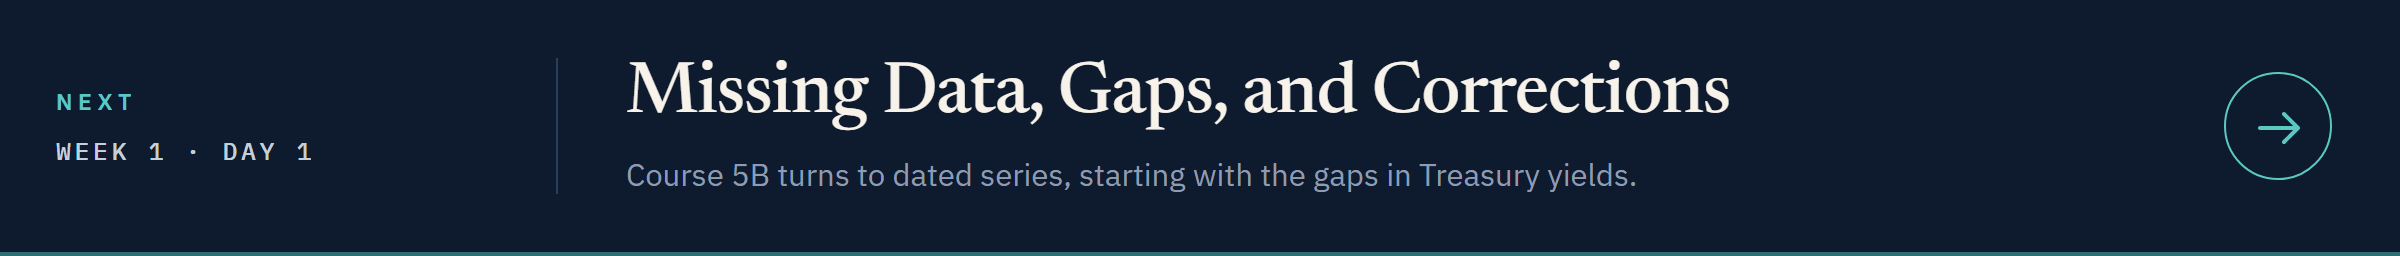](../../../course05b_time_series/week1/day1/01_missing_data_gaps_and_corrections.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day1/01_missing_data_gaps_and_corrections.ipynb)